In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/red-wine-quality-cortez-et-al-2009")

print("Path to dataset files:", path)

100%|██████████| 25.6k/25.6k [00:00<00:00, 33.2MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/uciml/red-wine-quality-cortez-et-al-2009/versions/2


In [2]:
# Import libraries
import kagglehub
import pandas as pd
import os

# Download the dataset (runs only once)
path = kagglehub.dataset_download("uciml/red-wine-quality-cortez-et-al-2009")

print("Dataset downloaded to:", path)

# Find the CSV file automatically
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]

print("CSV File:", csv_files[0])

# Load the dataset
df = pd.read_csv(os.path.join(path, csv_files[0]))

# Display the first 5 rows
print("\nFirst 5 Rows:")
print(df.head())

# Display last 5 rows
print("\nLast 5 Rows:")
print(df.tail())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display dataset shape
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display data types
print("\nData Types:")
print(df.dtypes)

# Display summary statistics
print("\nSummary Statistics:")
print(df.describe())

Using Colab cache for faster access to the 'red-wine-quality-cortez-et-al-2009' dataset.
Dataset downloaded to: /kaggle/input/red-wine-quality-cortez-et-al-2009
CSV File: winequality-red.csv

First 5 Rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0       

In [3]:
# Number of rows and columns
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Data types of each column
print("\nData Types:")
print(df.dtypes)

# Missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# Total missing values in the dataset
print("\nTotal Missing Values:", df.isnull().sum().sum())

Number of Rows: 1599
Number of Columns: 12

Data Types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total Missing Values: 0


In [4]:
# Display the first 5 records
print("First 5 Records:")
print(df.head())

# Display the last 5 records
print("\nLast 5 Records:")
print(df.tail())

# Display 5 randomly selected records
print("\nRandom 5 Records:")
print(df.sample(5, random_state=42))

First 5 Records:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2  

In [5]:
# Check missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# -------------------------------
# Handling Missing Values
# -------------------------------

# 1. Fill numerical columns with median
df.fillna(df.median(numeric_only=True), inplace=True)

# 2. Fill categorical columns with mode (if any)
for col in df.select_dtypes(include='object').columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

# 3. Interpolation (optional for numerical data)
df.interpolate(inplace=True)

# 4. Remove any remaining missing values (if any)
df.dropna(inplace=True)

# Verify that missing values are handled
print("\nMissing Values After Handling:")
print(df.isnull().sum())

print("\nTotal Missing Values After Handling:", df.isnull().sum().sum())

Missing values in each column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total Missing Values: 0

Missing Values After Handling:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total Missing Values After Handling: 0


In [6]:
# Check the number of duplicate records
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)

# Display duplicate records (if any)
print("\nDuplicate Records:")
print(df[df.duplicated()])

# Remove duplicate records
df = df.drop_duplicates()

# Verify duplicates have been removed
print("\nNumber of Duplicate Records After Removal:", df.duplicated().sum())

# Display the new dataset shape
print("\nDataset Shape After Removing Duplicates:")
print(df.shape)

Number of Duplicate Records: 240

Duplicate Records:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
4               7.4             0.700         0.00            1.90      0.076   
11              7.5             0.500         0.36            6.10      0.071   
27              7.9             0.430         0.21            1.60      0.106   
40              7.3             0.450         0.36            5.90      0.074   
65              7.2             0.725         0.05            4.65      0.086   
...             ...               ...          ...             ...        ...   
1563            7.2             0.695         0.13            2.00      0.076   
1564            7.2             0.695         0.13            2.00      0.076   
1567            7.2             0.695         0.13            2.00      0.076   
1581            6.2             0.560         0.09            1.70      0.053   
1596            6.3             0.510         0.13      

fixed acidity: 41 outliers
volatile acidity: 19 outliers
citric acid: 1 outliers
residual sugar: 126 outliers
chlorides: 87 outliers
free sulfur dioxide: 26 outliers
total sulfur dioxide: 45 outliers
density: 35 outliers
pH: 28 outliers
sulphates: 55 outliers
alcohol: 12 outliers
quality: 27 outliers


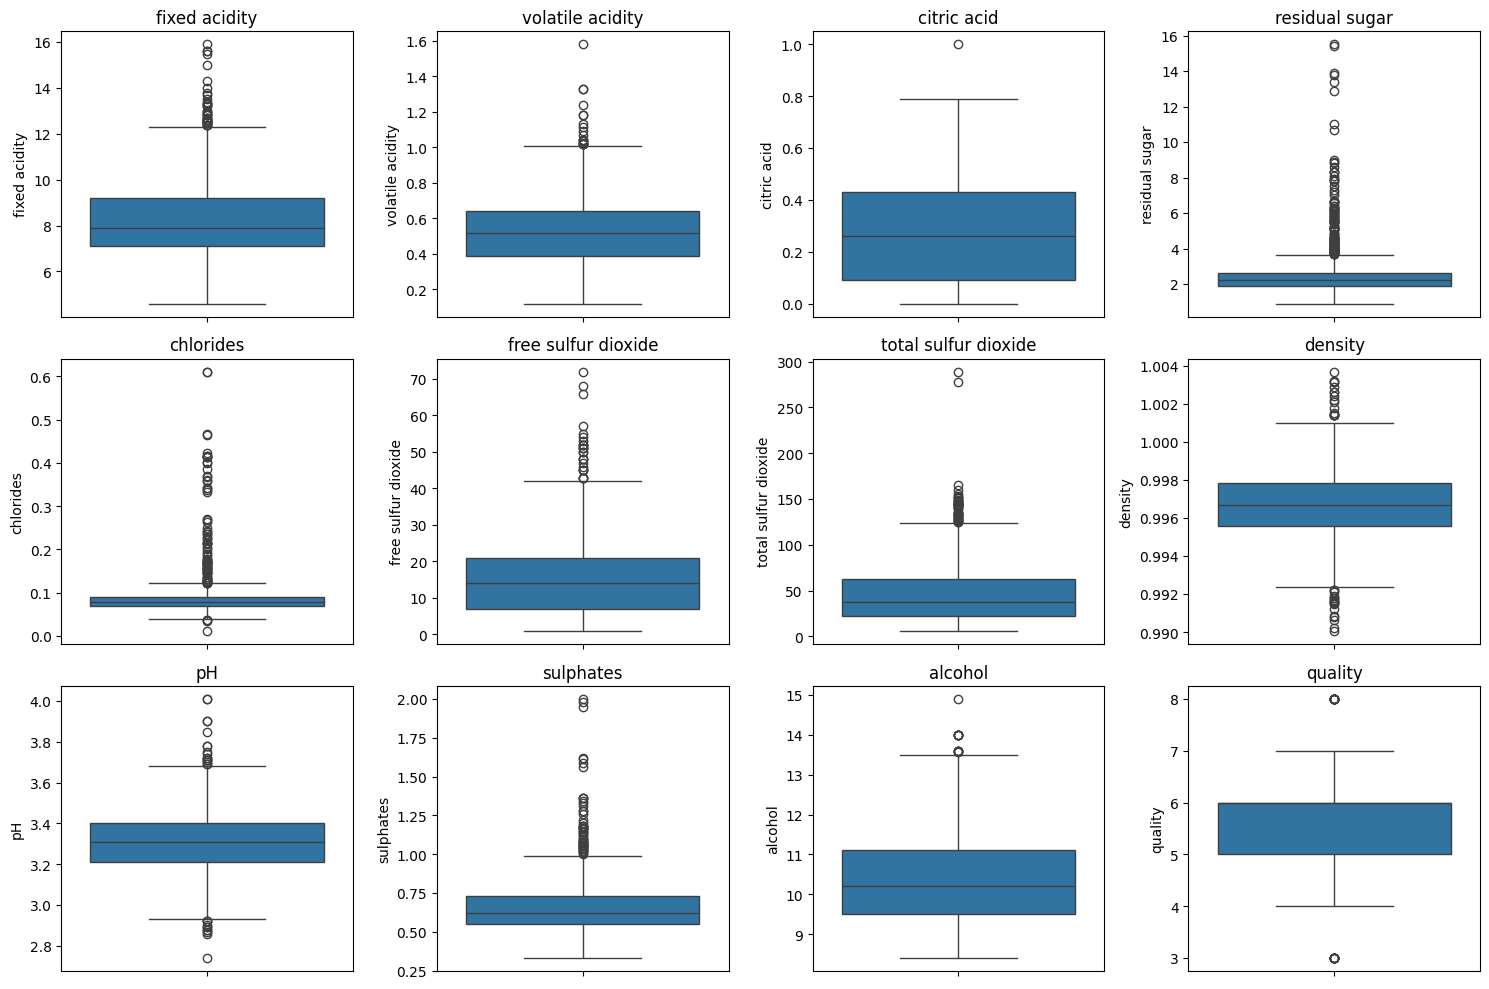

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Detect outliers using IQR
for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"{col}: {len(outliers)} outliers")

# Visualize outliers using box plots
plt.figure(figsize=(15, 10))

for i, col in enumerate(numeric_columns, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Dataset Shape After Removing Outliers:
(974, 12)


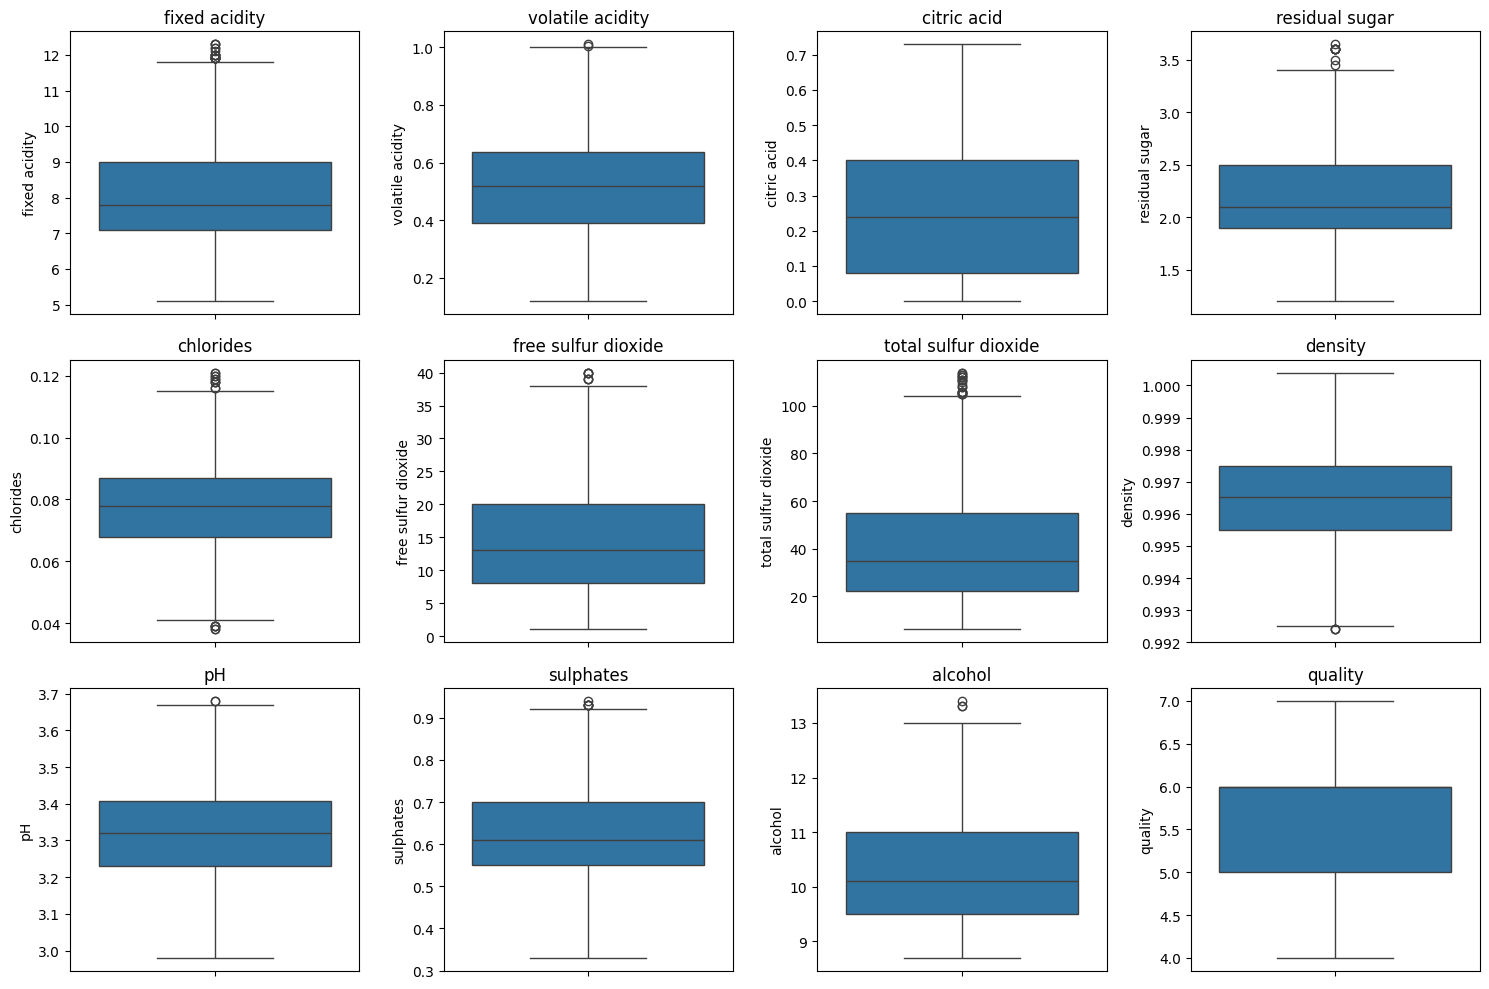

In [8]:
# Select numerical columns
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Remove outliers using IQR
for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Keep only rows within the IQR range
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

# Display the new dataset shape
print("Dataset Shape After Removing Outliers:")
print(df.shape)

# Verify with box plots
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numeric_columns, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [9]:
# Create a sample categorical column based on wine quality
df['Quality_Category'] = df['quality'].apply(
    lambda x: 'Low' if x <= 5 else ('Medium' if x == 6 else 'High')
)

print(df[['quality', 'Quality_Category']].head())

   quality Quality_Category
0        5              Low
1        5              Low
2        5              Low
3        6           Medium
5        5              Low


In [10]:
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
le = LabelEncoder()

# Apply Label Encoding
df['Quality_Label'] = le.fit_transform(df['Quality_Category'])

# Display results
print(df[['Quality_Category', 'Quality_Label']].head())

  Quality_Category  Quality_Label
0              Low              1
1              Low              1
2              Low              1
3           Medium              2
5              Low              1


In [11]:
# Apply One-Hot Encoding
df = pd.get_dummies(df, columns=['Quality_Category'])

# Display first 5 rows
print(df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
5            7.4              0.66         0.00             1.8      0.075   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
5                 13.0                  40.0   0.9978  3.51       0.56   

   alcohol  quality  Quality_Label  Quality_Category_High  \
0      9.4        5      

In [12]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Create copies of the dataset
df_minmax = df.copy()
df_standard = df.copy()

# Select numerical columns
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

# -----------------------------
# Min-Max Normalization
# -----------------------------
minmax_scaler = MinMaxScaler()

df_minmax[numeric_columns] = minmax_scaler.fit_transform(df_minmax[numeric_columns])

print("Min-Max Normalized Data:")
print(df_minmax.head())

# -----------------------------
# Standardization (Z-score Scaling)
# -----------------------------
standard_scaler = StandardScaler()

df_standard[numeric_columns] = standard_scaler.fit_transform(df_standard[numeric_columns])

print("\nStandardized Data:")
print(df_standard.head())

Min-Max Normalized Data:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0       0.319444          0.651685     0.000000        0.285714   0.457831   
1       0.375000          0.853933     0.000000        0.571429   0.722892   
2       0.375000          0.719101     0.054795        0.448980   0.650602   
3       0.847222          0.179775     0.767123        0.285714   0.445783   
5       0.319444          0.606742     0.000000        0.244898   0.445783   

   free sulfur dioxide  total sulfur dioxide  density        pH  sulphates  \
0             0.256410              0.259259    0.675  0.757143   0.377049   
1             0.615385              0.564815    0.550  0.314286   0.573770   
2             0.358974              0.444444    0.575  0.400000   0.524590   
3             0.410256              0.500000    0.700  0.257143   0.409836   
5             0.307692              0.314815    0.675  0.757143   0.377049   

    alcohol   quality  Quality_Label 

In [13]:
# Calculate the correlation matrix
correlation_matrix = df.corr(numeric_only=True)

# Display the correlation of all features with the target variable 'quality'
print("Correlation with Quality:\n")
print(correlation_matrix["quality"].sort_values(ascending=False))

# Select relevant features with correlation greater than 0.2 or less than -0.2
selected_features = correlation_matrix["quality"][
    abs(correlation_matrix["quality"]) > 0.2
]

print("\nSelected Features:")
print(selected_features)

Correlation with Quality:

quality                    1.000000
Quality_Category_High      0.688320
alcohol                    0.494724
sulphates                  0.441282
Quality_Category_Medium    0.434257
citric acid                0.233362
fixed acidity              0.131363
residual sugar             0.030616
free sulfur dioxide       -0.008276
Quality_Label             -0.012651
pH                        -0.072304
chlorides                 -0.179835
total sulfur dioxide      -0.183427
density                   -0.210315
volatile acidity          -0.352827
Quality_Category_Low      -0.877799
Name: quality, dtype: float64

Selected Features:
volatile acidity          -0.352827
citric acid                0.233362
density                   -0.210315
sulphates                  0.441282
alcohol                    0.494724
quality                    1.000000
Quality_Category_High      0.688320
Quality_Category_Low      -0.877799
Quality_Category_Medium    0.434257
Name: quality, dtype: f

Correlation Matrix:
                         fixed acidity  volatile acidity  citric acid  \
fixed acidity                 1.000000         -0.283759     0.652919   
volatile acidity             -0.283759          1.000000    -0.621891   
citric acid                   0.652919         -0.621891     1.000000   
residual sugar                0.225130          0.022663     0.144538   
chlorides                     0.181934          0.131111     0.049734   
free sulfur dioxide          -0.148817         -0.012718    -0.076354   
total sulfur dioxide         -0.098714          0.102185    -0.000254   
density                       0.596158          0.047526     0.276727   
pH                           -0.698744          0.244223    -0.476373   
sulphates                     0.168387         -0.320383     0.276078   
alcohol                      -0.019642         -0.230791     0.161172   
quality                       0.131363         -0.352827     0.233362   
Quality_Label                -0

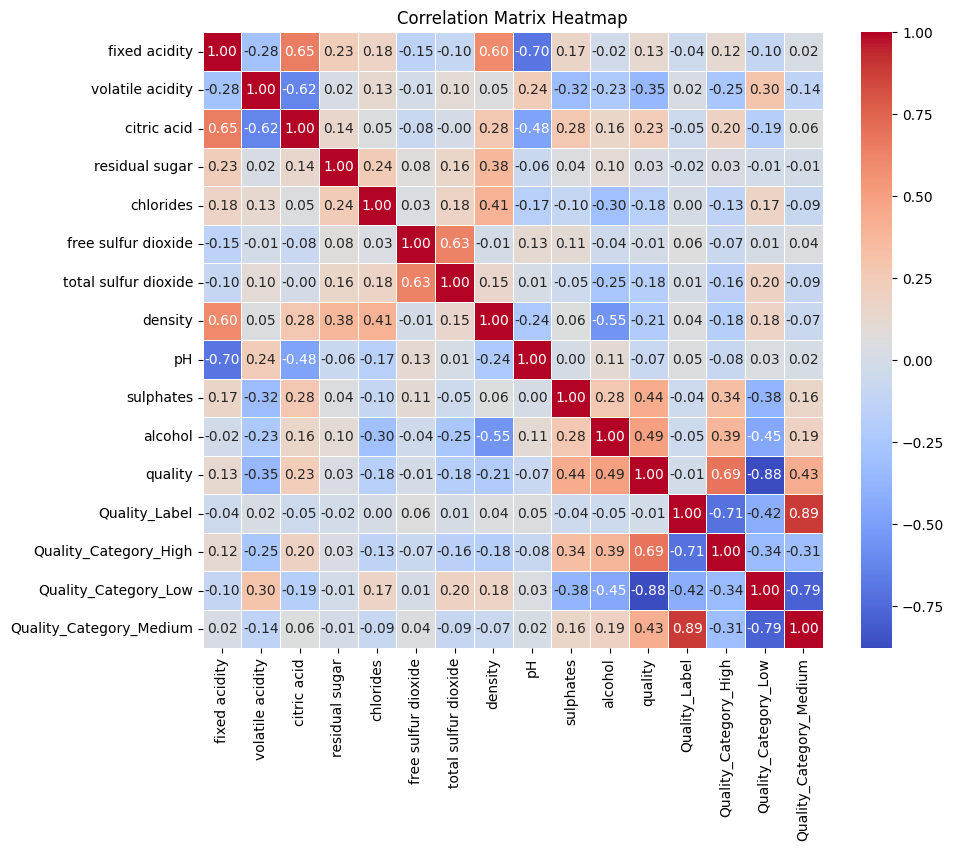

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Generate the correlation matrix
correlation_matrix = df.corr(numeric_only=True)

# Display the correlation matrix
print("Correlation Matrix:")
print(correlation_matrix)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,
            annot=True,
            cmap="coolwarm",
            fmt=".2f",
            linewidths=0.5)

plt.title("Correlation Matrix Heatmap")
plt.show()

In [15]:
# Create a new feature: Acidity Ratio
df['Acidity_Ratio'] = df['fixed acidity'] / df['volatile acidity']

# Create a new feature: Total Sulfur
df['Total_Sulfur'] = df['free sulfur dioxide'] + df['total sulfur dioxide']

# Create a new feature: Alcohol per Density
df['Alcohol_Density_Ratio'] = df['alcohol'] / df['density']

# Display the first 5 rows with the new features
print(df[['Acidity_Ratio', 'Total_Sulfur', 'Alcohol_Density_Ratio']].head())

   Acidity_Ratio  Total_Sulfur  Alcohol_Density_Ratio
0      10.571429          45.0               9.420726
1       8.863636          92.0               9.831461
2      10.263158          69.0               9.829488
3      40.000000          77.0               9.819639
5      11.212121          53.0               9.420726


In [16]:
# Display data types before conversion
print("Data Types Before Conversion:\n")
print(df.dtypes)

# Convert 'quality' column from integer to float
df['quality'] = df['quality'].astype(float)

# Display data types after conversion
print("\nData Types After Conversion:\n")
print(df.dtypes)

Data Types Before Conversion:

fixed acidity              float64
volatile acidity           float64
citric acid                float64
residual sugar             float64
chlorides                  float64
free sulfur dioxide        float64
total sulfur dioxide       float64
density                    float64
pH                         float64
sulphates                  float64
alcohol                    float64
quality                      int64
Quality_Label                int64
Quality_Category_High         bool
Quality_Category_Low          bool
Quality_Category_Medium       bool
Acidity_Ratio              float64
Total_Sulfur               float64
Alcohol_Density_Ratio      float64
dtype: object

Data Types After Conversion:

fixed acidity              float64
volatile acidity           float64
citric acid                float64
residual sugar             float64
chlorides                  float64
free sulfur dioxide        float64
total sulfur dioxide       float64
density       

In [17]:
# Display dataset shape before cleaning
print("Dataset Shape Before Cleaning:", df.shape)

# Remove duplicate records (if any)
df.drop_duplicates(inplace=True)

# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Clip extreme values (outliers) using the 1st and 99th percentiles
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_columns:
    lower = df[col].quantile(0.01)
    upper = df[col].quantile(0.99)
    df[col] = df[col].clip(lower, upper)

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display dataset shape after cleaning
print("\nDataset Shape After Cleaning:", df.shape)

# Display the first 5 rows
print("\nCleaned Dataset:")
print(df.head())

Dataset Shape Before Cleaning: (974, 19)

Missing Values:
fixed acidity              0
volatile acidity           0
citric acid                0
residual sugar             0
chlorides                  0
free sulfur dioxide        0
total sulfur dioxide       0
density                    0
pH                         0
sulphates                  0
alcohol                    0
quality                    0
Quality_Label              0
Quality_Category_High      0
Quality_Category_Low       0
Quality_Category_Medium    0
Acidity_Ratio              0
Total_Sulfur               0
Alcohol_Density_Ratio      0
dtype: int64

Dataset Shape After Cleaning: (974, 19)

Cleaned Dataset:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3      

In [18]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df.drop("quality", axis=1)
y = df["quality"]

# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display the shapes of the datasets
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

Training Features Shape: (779, 18)
Testing Features Shape: (195, 18)
Training Labels Shape: (779,)
Testing Labels Shape: (195,)


In [19]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

# Define features (X) and target (y)
X = df.drop("quality", axis=1)
y = df["quality"]

# Display class distribution before balancing
print("Before Balancing:")
print(Counter(y))

# Apply Random Oversampling
ros = RandomOverSampler(random_state=42)
X_resampled, y_resampled = ros.fit_resample(X, y)

# Display class distribution after balancing
print("\nAfter Balancing:")
print(Counter(y_resampled))

Before Balancing:
Counter({5.0: 415, 6.0: 411, 7.0: 116, 4.0: 32})

After Balancing:
Counter({5.0: 415, 6.0: 415, 7.0: 415, 4.0: 415})


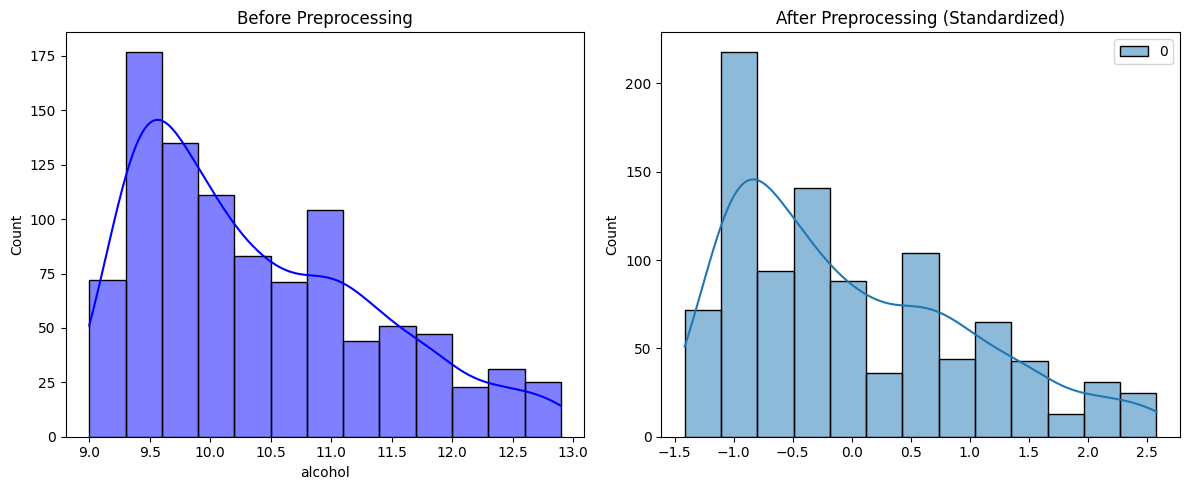

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Select a numerical feature
feature = "alcohol"

# Plot distribution before preprocessing
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(df[feature], kde=True, color="blue")
plt.title("Before Preprocessing")

# Apply Standardization
scaler = StandardScaler()
scaled_feature = scaler.fit_transform(df[[feature]])

# Plot distribution after preprocessing
plt.subplot(1,2,2)
sns.histplot(scaled_feature, kde=True, color="green")
plt.title("After Preprocessing (Standardized)")

plt.tight_layout()
plt.show()

In [21]:
df_original = df.copy()

In [22]:
# Display dataset information before preprocessing
print("===== BEFORE PREPROCESSING =====")
print("Shape:", df_original.shape)
print("\nMissing Values:")
print(df_original.isnull().sum())
print("\nDuplicate Records:", df_original.duplicated().sum())

# Display dataset information after preprocessing
print("\n===== AFTER PREPROCESSING =====")
print("Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Records:", df.duplicated().sum())

# Compare summary statistics
print("\n===== SUMMARY STATISTICS =====")
print(df.describe())

===== BEFORE PREPROCESSING =====
Shape: (974, 19)

Missing Values:
fixed acidity              0
volatile acidity           0
citric acid                0
residual sugar             0
chlorides                  0
free sulfur dioxide        0
total sulfur dioxide       0
density                    0
pH                         0
sulphates                  0
alcohol                    0
quality                    0
Quality_Label              0
Quality_Category_High      0
Quality_Category_Low       0
Quality_Category_Medium    0
Acidity_Ratio              0
Total_Sulfur               0
Alcohol_Density_Ratio      0
dtype: int64

Duplicate Records: 0

===== AFTER PREPROCESSING =====
Shape: (974, 19)

Missing Values:
fixed acidity              0
volatile acidity           0
citric acid                0
residual sugar             0
chlorides                  0
free sulfur dioxide        0
total sulfur dioxide       0
density                    0
pH                         0
sulphates          

In [24]:
# Save the cleaned dataset
df.to_csv("RedWine_Preprocessed.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
